# Import libraries

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

print("NumPy Version:", np.__version__)
print("OpenCV Version:", cv2.__version__)
print("Libraries imported successfully!")

NumPy Version: 2.4.6
OpenCV Version: 5.0.0
Libraries imported successfully!


# Loading image

Colour Image Shape: (1155, 650, 3)
Colour Image Data Type: uint8


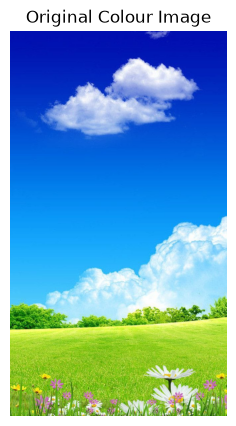

In [16]:
# Load original colour image
color_img = cv2.imread("img.jpeg")

if color_img is None:
    raise FileNotFoundError("Image not found. Check the file name.")

# Convert BGR to RGB for correct colour display
color_img = cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB)

print("Colour Image Shape:", color_img.shape)
print("Colour Image Data Type:", color_img.dtype)

plt.figure(figsize=(7, 5))
plt.imshow(color_img)
plt.title("Original Colour Image")
plt.axis("off")
plt.show()

# Grayscale image

Grayscale Image Shape: (1155, 650)
Image Data Type: uint8
Minimum Intensity: 3
Maximum Intensity: 255


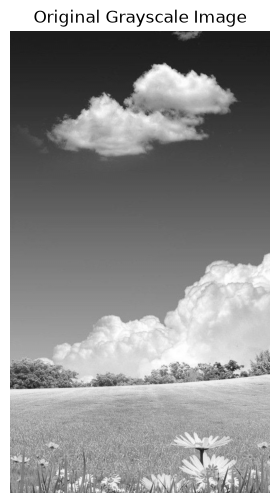

In [4]:
# Convert colour image into grayscale

img = cv2.imread("img.jpeg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Image not found. Check img.jpeg file.")

if img.dtype != np.uint8:
    raise ValueError("Image must be 8-bit grayscale.")

original = img.copy()

print("Grayscale Image Shape:", img.shape)
print("Image Data Type:", img.dtype)
print("Minimum Intensity:", img.min())
print("Maximum Intensity:", img.max())

plt.figure(figsize=(6, 6))
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

# Brighteness adjustment

DRY RUN - Brightness Increase
30 + 40 = 70 Final = 70
80 + 40 = 120 Final = 120
128 + 40 = 168 Final = 168
180 + 40 = 220 Final = 220
240 + 40 = 280 Final = 255

DRY RUN - Brightness Decrease
30 - 40 = -10 Final = 0
80 - 40 = 40 Final = 40
128 - 40 = 88 Final = 88
180 - 40 = 140 Final = 140
240 - 40 = 200 Final = 200
T1a: Original Image Shape: (1155, 650)
T1b: Brightness increased by 40
T1c: Brightness decreased by 40
T1d: Nested loop brightness adjustment completed


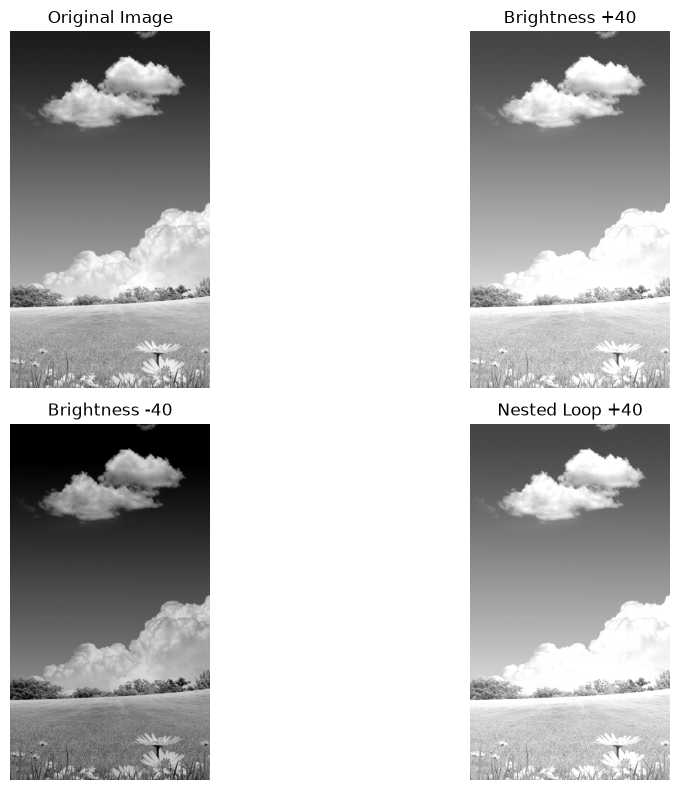

In [5]:
# DRY RUN
pixels = [30, 80, 128, 180, 240]

print("DRY RUN - Brightness Increase")
for r in pixels:
    raw = r + 40
    print(r, "+ 40 =", raw, "Final =", min(raw, 255))

print("\nDRY RUN - Brightness Decrease")
for r in pixels:
    raw = r - 40
    print(r, "- 40 =", raw, "Final =", max(raw, 0))

# Task 1: Brightness Adjustment

# Increase brightness by 40
bright_img = np.clip(original.astype(np.int16) + 40, 0, 255).astype(np.uint8)

# Decrease brightness by 40
dark_img = np.clip(original.astype(np.int16) - 40, 0, 255).astype(np.uint8)

# Increase brightness using nested loops
loop_img = original.copy()

for i in range(loop_img.shape[0]):
    for j in range(loop_img.shape[1]):
        loop_img[i, j] = min(int(original[i, j]) + 40, 255)

print("T1a: Original Image Shape:", original.shape)
print("T1b: Brightness increased by 40")
print("T1c: Brightness decreased by 40")
print("T1d: Nested loop brightness adjustment completed")

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(bright_img, cmap="gray", vmin=0, vmax=255)
plt.title("Brightness +40")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(dark_img, cmap="gray", vmin=0, vmax=255)
plt.title("Brightness -40")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(loop_img, cmap="gray", vmin=0, vmax=255)
plt.title("Nested Loop +40")
plt.axis("off")

plt.tight_layout()
plt.show()

# Linear Contrast Enhancement

DRY RUN - Linear Contrast
30 x 1.5 = 45.0, Final = 45
80 x 1.5 = 120.0, Final = 120
128 x 1.5 = 192.0, Final = 192
180 x 1.5 = 270.0, Final = 255
240 x 1.5 = 360.0, Final = 255
T2a: Contrast Factor: 1.5
T2b: Brightness Offset: 0
T2c: Linear contrast enhancement completed.


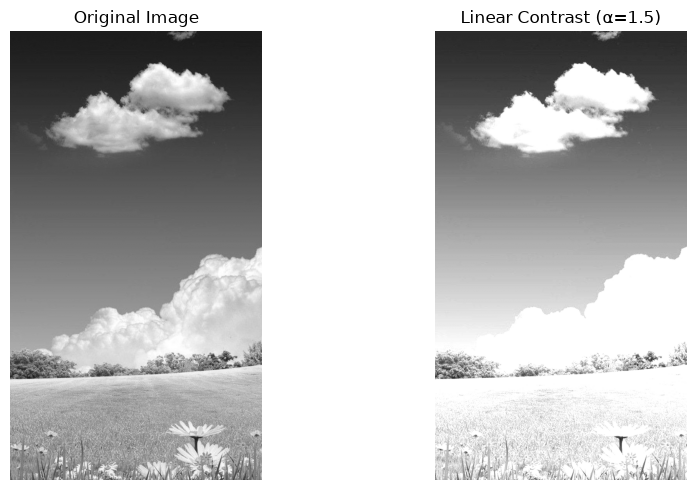

In [6]:
# DRY RUN
pixels = [30, 80, 128, 180, 240]

print("DRY RUN - Linear Contrast")
for r in pixels:
    raw = 1.5 * r
    print(f"{r} x 1.5 = {raw}, Final = {int(np.clip(raw, 0, 255))}")
# Task 2: Linear Contrast Enhancement

alpha = 1.5
beta = 0

contrast_zero = np.clip(
    alpha * original.astype(np.float32) + beta,
    0, 255
).astype(np.uint8)

print("T2a: Contrast Factor:", alpha)
print("T2b: Brightness Offset:", beta)
print("T2c: Linear contrast enhancement completed.")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast_zero, cmap="gray", vmin=0, vmax=255)
plt.title("Linear Contrast (α=1.5)")
plt.axis("off")

plt.tight_layout()
plt.show()

# Centered Contrast Enhancement


DRY RUN - Alpha = 1.5
Pixel 30: Raw = -19.0, Final = 0
Pixel 80: Raw = 56.0, Final = 56
Pixel 128: Raw = 128.0, Final = 128
Pixel 180: Raw = 206.0, Final = 206
Pixel 240: Raw = 296.0, Final = 255

DRY RUN - Alpha = 0.5
Pixel 30: Raw = 79.0, Final = 79
Pixel 80: Raw = 104.0, Final = 104
Pixel 128: Raw = 128.0, Final = 128
Pixel 180: Raw = 154.0, Final = 154
Pixel 240: Raw = 184.0, Final = 184
T3a: Contrast increased with alpha = 1.5
T3b: Contrast decreased with alpha = 0.5
T3c: Centered contrast enhancement completed.


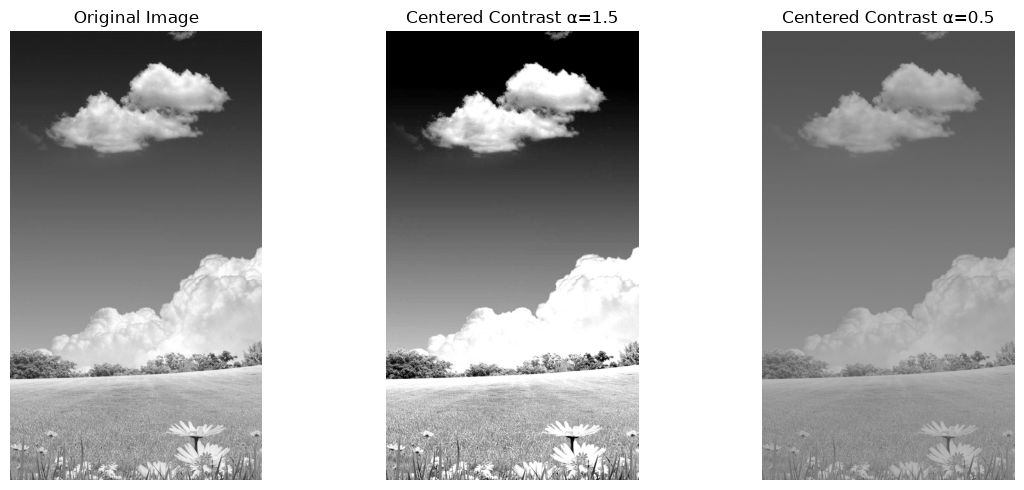

In [7]:
# DRY RUN
pixels = [30, 80, 128, 180, 240]

for alpha in [1.5, 0.5]:
    print(f"\nDRY RUN - Alpha = {alpha}")
    for r in pixels:
        raw = (r - 128) * alpha + 128
        print(f"Pixel {r}: Raw = {raw}, Final = {int(np.clip(raw, 0, 255))}")
# Task 3: Centered Contrast Enhancement

contrast_15 = np.clip(
    (original.astype(np.float32) - 128) * 1.5 + 128,
    0, 255
).astype(np.uint8)

contrast_05 = np.clip(
    (original.astype(np.float32) - 128) * 0.5 + 128,
    0, 255
).astype(np.uint8)

print("T3a: Contrast increased with alpha = 1.5")
print("T3b: Contrast decreased with alpha = 0.5")
print("T3c: Centered contrast enhancement completed.")

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(contrast_15, cmap="gray", vmin=0, vmax=255)
plt.title("Centered Contrast α=1.5")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(contrast_05, cmap="gray", vmin=0, vmax=255)
plt.title("Centered Contrast α=0.5")
plt.axis("off")

plt.tight_layout()
plt.show()

# Image Negative

DRY RUN - Image Negative
255 - 30 = 225
255 - 80 = 175
255 - 128 = 127
255 - 180 = 75
255 - 240 = 15

Negative Applied Twice
255 - 225 = 30
255 - 175 = 80
255 - 127 = 128
255 - 75 = 180
255 - 15 = 240
T4a: Negative transformation completed.
T4b: Negative transformation applied twice.
T4c: Original and recovered images are identical: True


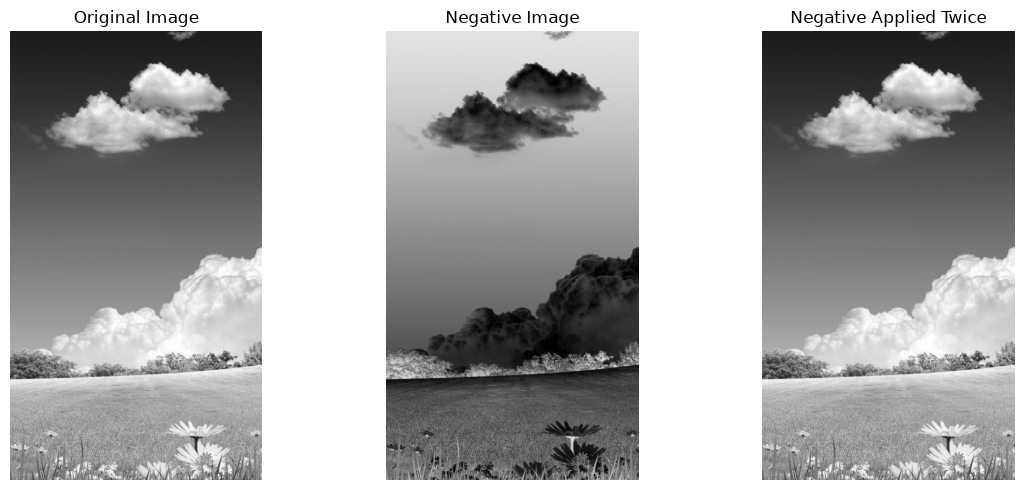

In [8]:

# DRY RUN
pixels = [30, 80, 128, 180, 240]

print("DRY RUN - Image Negative")
negative_pixels = []

for r in pixels:
    result = 255 - r
    negative_pixels.append(result)
    print(f"255 - {r} = {result}")

print("\nNegative Applied Twice")
for r in negative_pixels:
    print(f"255 - {r} = {255 - r}")# Task 4: Image Negative Transformation

negative_img = 255 - original

# Apply negative transformation again
recovered_img = 255 - negative_img

print("T4a: Negative transformation completed.")
print("T4b: Negative transformation applied twice.")

print("T4c: Original and recovered images are identical:",
      np.array_equal(original, recovered_img))

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(negative_img, cmap="gray", vmin=0, vmax=255)
plt.title("Negative Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(recovered_img, cmap="gray", vmin=0, vmax=255)
plt.title("Negative Applied Twice")
plt.axis("off")

plt.tight_layout()
plt.show()

# Gamma Correction


DRY RUN - Gamma = 0.5
Pixel = 0, Raw = 0.0000, Final = 0
Pixel = 64, Raw = 127.7498, Final = 127
Pixel = 128, Raw = 180.6654, Final = 180
Pixel = 192, Raw = 221.2691, Final = 221
Pixel = 255, Raw = 255.0000, Final = 255

DRY RUN - Gamma = 2.0
Pixel = 0, Raw = 0.0000, Final = 0
Pixel = 64, Raw = 16.0627, Final = 16
Pixel = 128, Raw = 64.2510, Final = 64
Pixel = 192, Raw = 144.5647, Final = 144
Pixel = 255, Raw = 255.0000, Final = 255
T5a: Gamma 0.5 applied successfully.
T5b: Gamma 2.0 applied successfully.


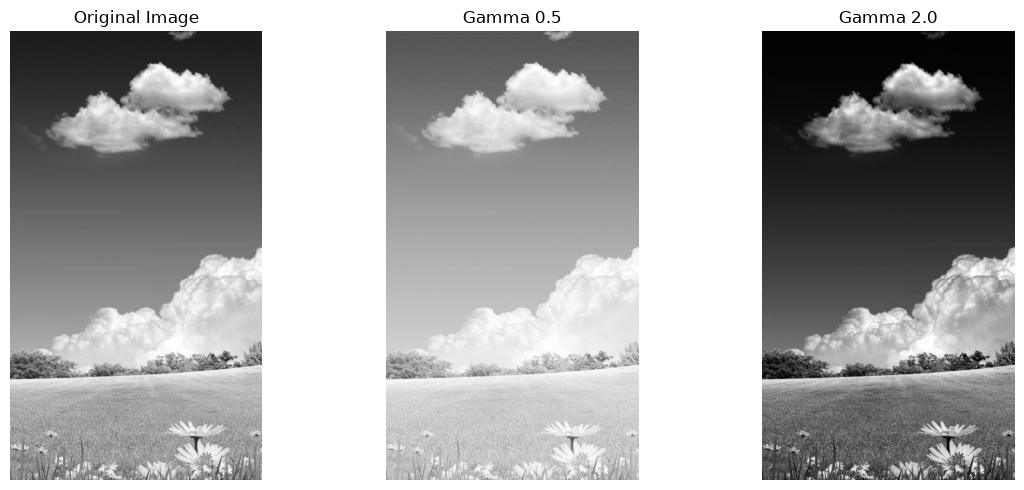

In [9]:
# DRY RUN
pixels = [0, 64, 128, 192, 255]

for gamma in [0.5, 2.0]:
    print(f"\nDRY RUN - Gamma = {gamma}")
    for r in pixels:
        raw = 255 * (r / 255) ** gamma
        print(f"Pixel = {r}, Raw = {raw:.4f}, Final = {int(raw)}")
# Task 5: Gamma Correction

normalized = original.astype(np.float64) / 255

gamma_05 = (255 * normalized**0.5).astype(np.uint8)
gamma_20 = (255 * normalized**2.0).astype(np.uint8)

print("T5a: Gamma 0.5 applied successfully.")
print("T5b: Gamma 2.0 applied successfully.")

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gamma_05, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma 0.5")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gamma_20, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma 2.0")
plt.axis("off")

plt.tight_layout()
plt.show()

# Image Histogram

DRY RUN - Histogram
Intensity: 0 Frequency: 1 Probability: 0.125
Intensity: 50 Frequency: 2 Probability: 0.25
Intensity: 100 Frequency: 2 Probability: 0.25
Intensity: 150 Frequency: 1 Probability: 0.125
Intensity: 200 Frequency: 1 Probability: 0.125
Intensity: 255 Frequency: 1 Probability: 0.125
Total Pixels: 8
T6a: Histogram Shape: (256,)
T6b: Total Number of Pixels: 750750
T6c: Dark Pixels (0-85): 191244
T6d: Medium Pixels (86-170): 343190
T6e: Bright Pixels (171-255): 216316


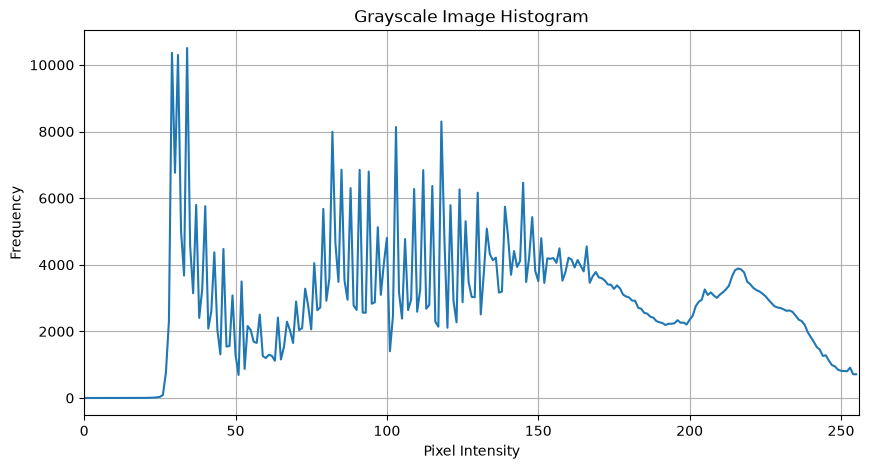

In [10]:
# DRY RUN
A = np.array([
    [0, 50, 50, 100],
    [100, 150, 200, 255]
])

values, counts = np.unique(A, return_counts=True)

print("DRY RUN - Histogram")
for value, count in zip(values, counts):
    print(
        "Intensity:", value,
        "Frequency:", count,
        "Probability:", count / A.size
    )

print("Total Pixels:", A.size)
# Task 6: Image Histogram

hist = cv2.calcHist([original], [0], None, [256], [0, 256])

print("T6a: Histogram Shape:", hist.shape)
print("T6b: Total Number of Pixels:", original.size)
print("T6c: Dark Pixels (0-85):", int(hist[:86].sum()))
print("T6d: Medium Pixels (86-170):", int(hist[86:171].sum()))
print("T6e: Bright Pixels (171-255):", int(hist[171:].sum()))

plt.figure(figsize=(10, 5))
plt.plot(hist)
plt.title("Grayscale Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])
plt.grid()
plt.show()

# Global Histogram Equalization

DRY RUN - Histogram Equalization
Intensity: 50, Frequency: 2, CDF: 0.50, Method 1: 128, Method 2: 0
Intensity: 100, Frequency: 1, CDF: 0.75, Method 1: 191, Method 2: 128
Intensity: 150, Frequency: 1, CDF: 1.00, Method 1: 255, Method 2: 255
T7a: Original Image Shape: (1155, 650)
T7b: Equalized Image Shape: (1155, 650)
T7c: Histogram Equalization completed successfully.


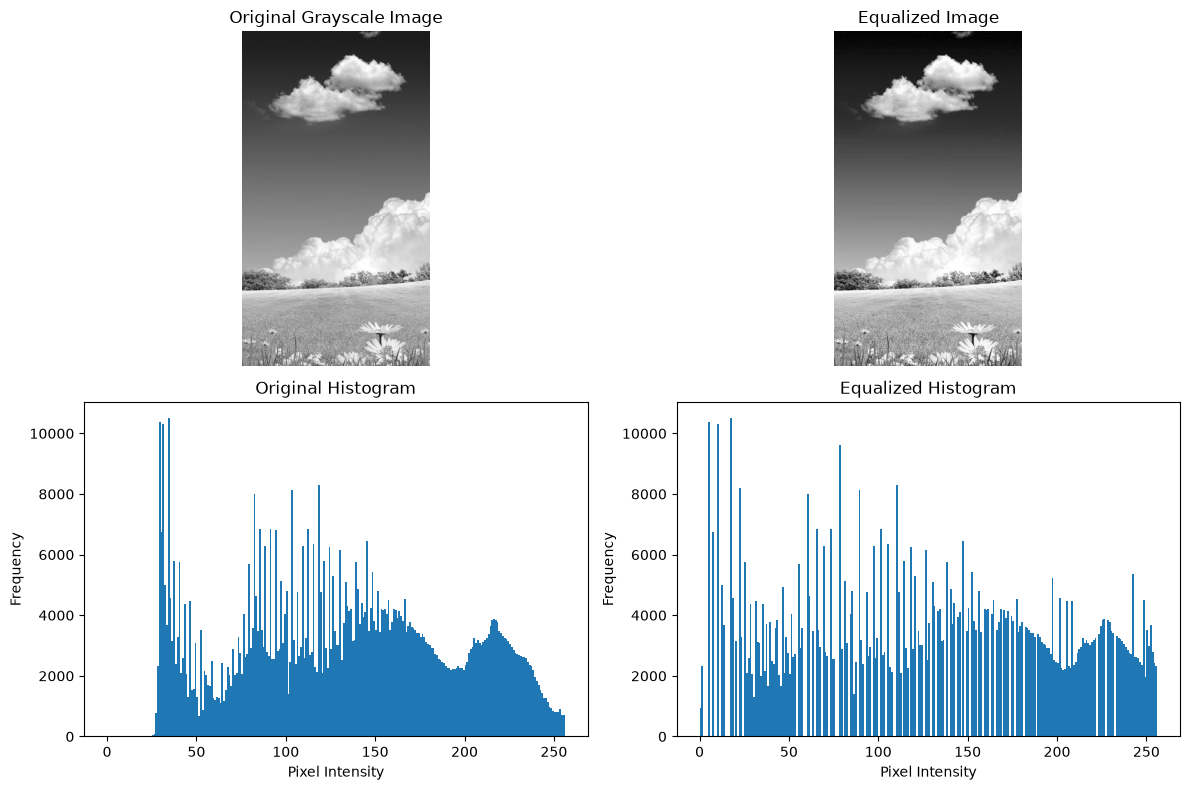

In [11]:
# DRY RUN
pixels = [50, 50, 100, 150]

values, counts = np.unique(pixels, return_counts=True)
cdf = np.cumsum(counts) / len(pixels)
cdf_min = cdf[0]

print("DRY RUN - Histogram Equalization")

for value, count, cumulative in zip(values, counts, cdf):
    method1 = int(np.floor(255 * cumulative + 0.5))
    method2 = int(np.floor(
        255 * (cumulative - cdf_min) / (1 - cdf_min) + 0.5
    ))

    print(
        f"Intensity: {value}, Frequency: {count}, "
        f"CDF: {cumulative:.2f}, "
        f"Method 1: {method1}, Method 2: {method2}"
    )

# Task 7: Global Histogram Equalization

equalized_img = cv2.equalizeHist(original)

print("T7a: Original Image Shape:", original.shape)
print("T7b: Equalized Image Shape:", equalized_img.shape)
print("T7c: Histogram Equalization completed successfully.")

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(equalized_img, cmap="gray", vmin=0, vmax=255)
plt.title("Equalized Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.hist(original.ravel(), bins=256, range=(0, 256))
plt.title("Original Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.subplot(2, 2, 4)
plt.hist(equalized_img.ravel(), bins=256, range=(0, 256))
plt.title("Equalized Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# CLAHE

DRY RUN - CLAHE
Original Histogram: [6. 2. 0. 0.]
Clipped Histogram: [4. 2. 0. 0.]
Excess: 2.0
Redistributed Histogram: [4.5 2.5 0.5 0.5]
New CDF: [0.5625 0.875  0.9375 1.    ]
T8a: Clip Limit: 2.0
T8b: Tile Grid Size: (8, 8)
T8c: CLAHE applied successfully.


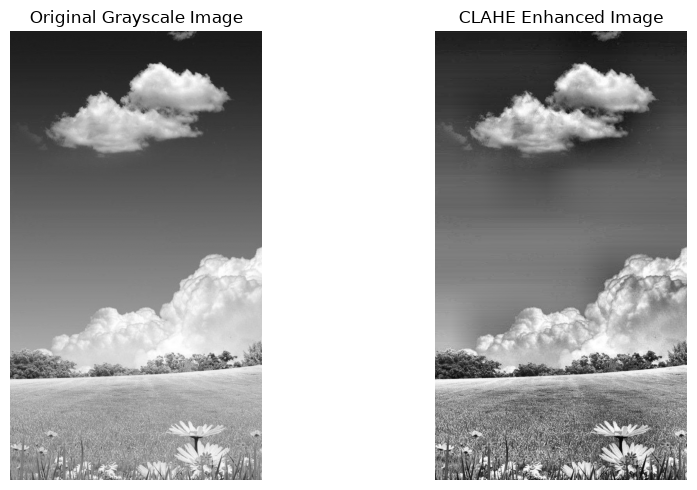

In [12]:
# DRY RUN
histogram_sample = np.array([6, 2, 0, 0], dtype=float)
clip_limit = 4

clipped = np.minimum(histogram_sample, clip_limit)
excess = np.sum(histogram_sample - clipped)
redistributed = clipped + excess / len(clipped)
cdf = np.cumsum(redistributed) / np.sum(redistributed)

print("DRY RUN - CLAHE")
print("Original Histogram:", histogram_sample)
print("Clipped Histogram:", clipped)
print("Excess:", excess)
print("Redistributed Histogram:", redistributed)
print("New CDF:", cdf)

# Task 8: CLAHE

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_img = clahe.apply(original)

print("T8a: Clip Limit:", 2.0)
print("T8b: Tile Grid Size:", (8, 8))
print("T8c: CLAHE applied successfully.")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clahe_img, cmap="gray", vmin=0, vmax=255)
plt.title("CLAHE Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Fixed Thresholding


DRY RUN - Threshold = 127
Input: [0, 80, 127, 128, 180, 255]
Output: [0, 0, 0, 255, 255, 255]
White Pixel Count: 3

DRY RUN - Threshold = 180
Input: [0, 80, 127, 128, 180, 255]
Output: [0, 0, 0, 0, 0, 255]
White Pixel Count: 1
T9a: Threshold 127 applied successfully.
T9b: Threshold 180 applied successfully.


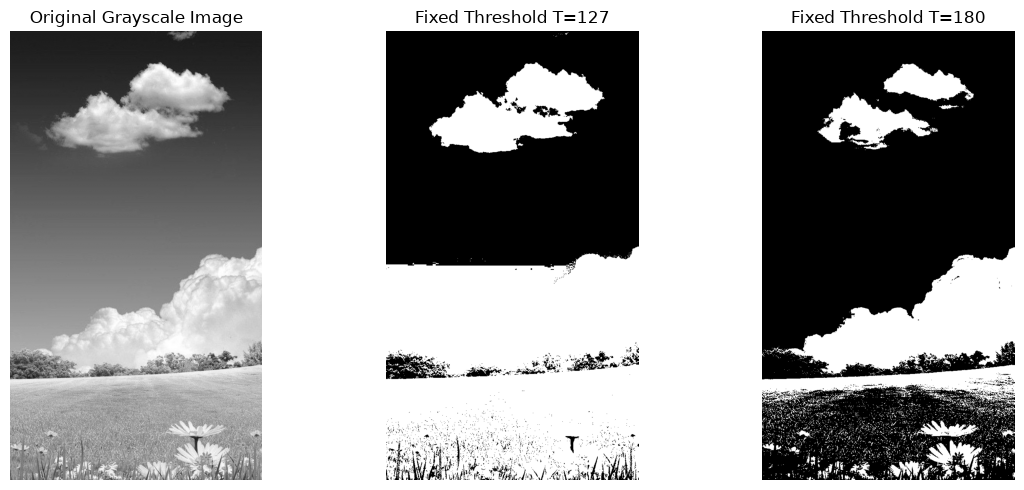

In [13]:
# DRY RUN
pixels = [0, 80, 127, 128, 180, 255]

for T in [127, 180]:
    output = [255 if r > T else 0 for r in pixels]

    print(f"\nDRY RUN - Threshold = {T}")
    print("Input:", pixels)
    print("Output:", output)
    print("White Pixel Count:", output.count(255))
# Task 9: Fixed Thresholding

# Threshold value 127
_, binary_img = cv2.threshold(
    original, 127, 255, cv2.THRESH_BINARY
)

# Threshold value 180
_, binary_180 = cv2.threshold(
    original, 180, 255, cv2.THRESH_BINARY
)

print("T9a: Threshold 127 applied successfully.")
print("T9b: Threshold 180 applied successfully.")

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_img, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Threshold T=127")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(binary_180, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Threshold T=180")
plt.axis("off")

plt.tight_layout()
plt.show()

# Otsu Thresholding

DRY RUN - Otsu Thresholding
T=0, Weight 0=0.25, Weight 1=0.75, Mean 0=0.00, Mean 1=3.33, Score=2.0833
T=1, Weight 0=0.50, Weight 1=0.50, Mean 0=0.50, Mean 1=4.50, Score=4.0000
T=2, Weight 0=0.50, Weight 1=0.50, Mean 0=0.50, Mean 1=4.50, Score=4.0000
T=3, Weight 0=0.50, Weight 1=0.50, Mean 0=0.50, Mean 1=4.50, Score=4.0000
T=4, Weight 0=0.75, Weight 1=0.25, Mean 0=1.67, Mean 1=5.00, Score=2.0833
Selected Dry Run Threshold: 1
Dry Run Output: [0, 0, 255, 255]
T10a: Otsu Threshold Value: 132.0
T10b: Otsu Thresholding completed successfully.


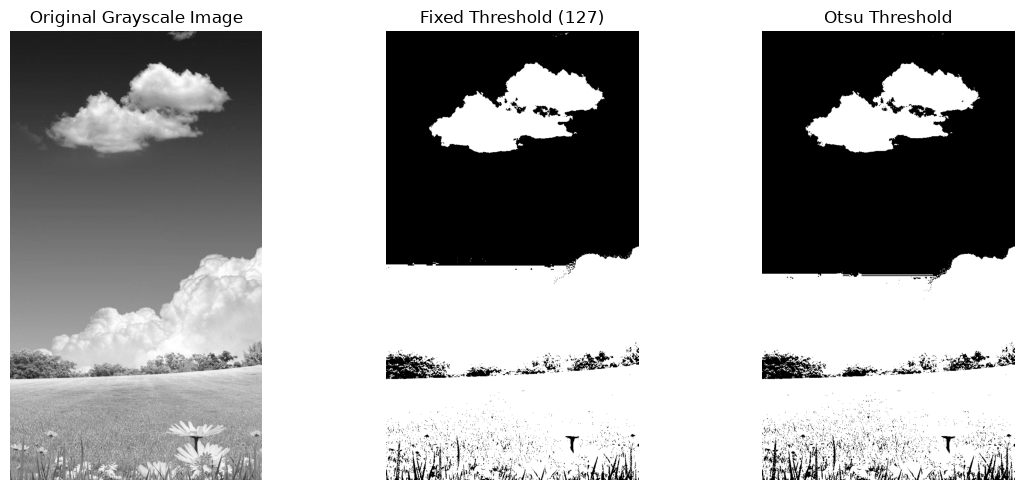

In [14]:
# DRY RUN
pixels = np.array([0, 1, 4, 5])
scores = []

print("DRY RUN - Otsu Thresholding")

for T in range(5):
    class0 = pixels[pixels <= T]
    class1 = pixels[pixels > T]

    if len(class0) == 0 or len(class1) == 0:
        score = 0
        w0 = len(class0) / len(pixels)
        w1 = len(class1) / len(pixels)
        mean0 = np.mean(class0) if len(class0) else 0
        mean1 = np.mean(class1) if len(class1) else 0
    else:
        w0 = len(class0) / len(pixels)
        w1 = len(class1) / len(pixels)
        mean0 = np.mean(class0)
        mean1 = np.mean(class1)
        score = w0 * w1 * (mean0 - mean1) ** 2

    scores.append(score)

    print(
        f"T={T}, Weight 0={w0:.2f}, Weight 1={w1:.2f}, "
        f"Mean 0={mean0:.2f}, Mean 1={mean1:.2f}, "
        f"Score={score:.4f}"
    )

best_threshold = scores.index(max(scores))

print("Selected Dry Run Threshold:", best_threshold)
print("Dry Run Output:", [
    255 if r > best_threshold else 0 for r in pixels
])
# Task 10: Otsu Thresholding

otsu_threshold, otsu_img = cv2.threshold(
    original,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("T10a: Otsu Threshold Value:", otsu_threshold)
print("T10b: Otsu Thresholding completed successfully.")

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_img, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Threshold (127)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(otsu_img, cmap="gray", vmin=0, vmax=255)
plt.title("Otsu Threshold")
plt.axis("off")

plt.tight_layout()
plt.show()

# Adaptive Guassian Thresholding

DRY RUN - Adaptive Gaussian
Weighted Sum: 1920
Total Weights: 16
Weighted Mean: 120.0
Threshold: 118.0
Center Pixel: 120
Center Pixel Output: 255
Pixel Equal to Threshold Output: 0
T11a: Block Size: 11
T11b: Constant C: 2
T11c: Adaptive Gaussian Thresholding completed.


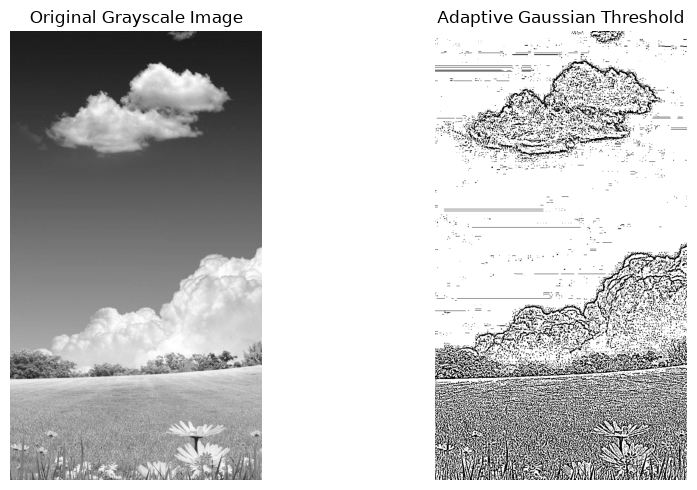

In [15]:
# DRY RUN
A = np.array([
    [100, 100, 100],
    [100, 120, 140],
    [140, 140, 140]
])

weights = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
])

weighted_sum = np.sum(A * weights)
total_weights = np.sum(weights)

mean = weighted_sum / total_weights
C = 2
T = mean - C

center_pixel = A[1, 1]
output = 255 if center_pixel > T else 0
equal_output = 255 if T > T else 0

print("DRY RUN - Adaptive Gaussian")
print("Weighted Sum:", weighted_sum)
print("Total Weights:", total_weights)
print("Weighted Mean:", mean)
print("Threshold:", T)
print("Center Pixel:", center_pixel)
print("Center Pixel Output:", output)
print("Pixel Equal to Threshold Output:", equal_output)
# Task 11: Adaptive Gaussian Thresholding

adaptive_img = cv2.adaptiveThreshold(
    original,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

print("T11a: Block Size:", 11)
print("T11b: Constant C:", 2)
print("T11c: Adaptive Gaussian Thresholding completed.")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(adaptive_img, cmap="gray", vmin=0, vmax=255)
plt.title("Adaptive Gaussian Threshold")
plt.axis("off")

plt.tight_layout()
plt.show()

## Saving All Generated Images

In this section, all original and processed images are saved separately in PNG format for future use.

In [15]:
# Save All Generated Images

all_images = {
    "01_Original_Colour.png": cv2.cvtColor(color_img, cv2.COLOR_RGB2BGR),
    "02_Original_Grayscale.png": original,
    "03_Brightness_Plus_40.png": bright_img,
    "04_Brightness_Minus_40.png": dark_img,
    "05_Linear_Contrast.png": contrast_zero,
    "06_Centered_Contrast_1_5.png": contrast_15,
    "07_Centered_Contrast_0_5.png": contrast_05,
    "08_Negative.png": negative_img,
    "09_Gamma_0_5.png": gamma_05,
    "10_Gamma_2_0.png": gamma_20,
    "11_Global_Equalization.png": equalized_img,
    "12_CLAHE.png": clahe_img,
    "13_Fixed_Threshold.png": binary_img,
    "14_Otsu_Threshold.png": otsu_img,
    "15_Adaptive_Gaussian.png": adaptive_img
}

for filename, image in all_images.items():
    cv2.imwrite(filename, image)

print("All 15 images saved successfully!")
print("Total images saved:", len(all_images))

All 15 images saved successfully!
Total images saved: 15
